# Hate speech: a TF-IDF + logistic regression baseline

I want to draw a clear line: this is a *baseline*, not a deployable classifier. The "hate speech" category is contested, label sets disagree with each other, and even well-funded production systems get this wrong in ways that matter. So I'm building the simplest reasonable thing on a public dataset and being explicit about scope.

**Dataset:** `tweet_eval/hate` from HuggingFace `datasets`. ~10k tweets, binary labels (hate / not hate).

In [1]:
# !pip install datasets scikit-learn -q

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score

ART = Path("artifacts"); ART.mkdir(exist_ok=True)
np.random.seed(7)

try:
    from datasets import load_dataset
    ds = load_dataset("tweet_eval", "hate")
    train_df = pd.DataFrame(ds["train"])
    val_df   = pd.DataFrame(ds["validation"])
    test_df  = pd.DataFrame(ds["test"])
    HAVE_DS = True
except Exception as e:
    HAVE_DS = False
    print("datasets unavailable:", repr(e)[:120])

README.md: 0.00B [00:00, ?B/s]

hate/train-00000-of-00001.parquet:   0%|          | 0.00/816k [00:00<?, ?B/s]

hate/test-00000-of-00001.parquet:   0%|          | 0.00/278k [00:00<?, ?B/s]

hate/validation-00000-of-00001.parquet:   0%|          | 0.00/103k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2970 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

In [3]:
if HAVE_DS:
    print("train:", train_df.shape, "val:", val_df.shape, "test:", test_df.shape)
    print(train_df["label"].value_counts(normalize=True).rename({0:"not_hate", 1:"hate"}))
    train_df.head(3)

train: (9000, 2) val: (1000, 2) test: (2970, 2)
label
not_hate    0.579667
hate        0.420333
Name: proportion, dtype: float64


## EDA — text length

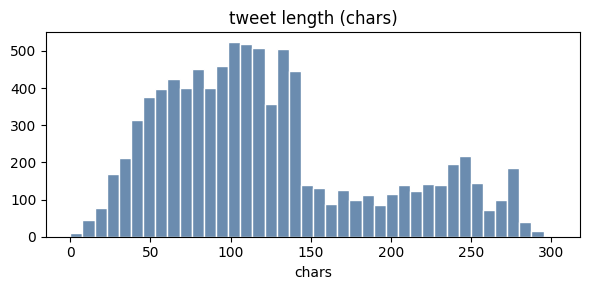

mean len: 122.836 max: 303


In [4]:
if HAVE_DS:
    lens = train_df["text"].str.len()
    fig, ax = plt.subplots(figsize=(6,3))
    ax.hist(lens, bins=40, color="#6b8caf", edgecolor="white")
    ax.set_title("tweet length (chars)"); ax.set_xlabel("chars")
    plt.tight_layout(); plt.savefig(ART/"text_len.png", dpi=110); plt.show()
    print("mean len:", lens.mean(), "max:", lens.max())

## TF-IDF + logreg

In [5]:
if HAVE_DS:
    # min_df=3 trims rare tokens — most are typos or hashtag fragments.
    vec = TfidfVectorizer(min_df=3, max_df=0.95, ngram_range=(1,2),
                          sublinear_tf=True, max_features=40_000)
    Xtr = vec.fit_transform(train_df["text"])
    Xva = vec.transform(val_df["text"])
    Xte = vec.transform(test_df["text"])
    ytr, yva, yte = train_df["label"].values, val_df["label"].values, test_df["label"].values

    clf = LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0)
    clf.fit(Xtr, ytr)

    for name, X, y in [("val", Xva, yva), ("test", Xte, yte)]:
        pred = clf.predict(X)
        print(f"{name}  macro-F1: {f1_score(y, pred, average='macro'):.3f}  acc: {(pred==y).mean():.3f}")
    print()
    print("test classification report:")
    print(classification_report(yte, clf.predict(Xte), target_names=["not_hate","hate"]))

val  macro-F1: 0.717  acc: 0.718
test  macro-F1: 0.406  acc: 0.469

test classification report:
              precision    recall  f1-score   support

    not_hate       0.74      0.12      0.21      1718
        hate       0.44      0.94      0.60      1252

    accuracy                           0.47      2970
   macro avg       0.59      0.53      0.41      2970
weighted avg       0.62      0.47      0.38      2970



## Most-weighted features (sanity check)

In [6]:
if HAVE_DS:
    coefs = clf.coef_[0]
    vocab = np.array(vec.get_feature_names_out())
    top_hate = vocab[np.argsort(-coefs)[:15]]
    top_not  = vocab[np.argsort(coefs)[:15]]
    print("strongest 'hate' tokens:", list(top_hate))
    print()
    print("strongest 'not hate' tokens:", list(top_not))

strongest 'hate' tokens: ['bitch', 'buildthatwall', 'womensuck', 'illegal', 'buildthewall', 'bitches', 'hoe', 'whore', 'maga', 'nodaca', 'illegals', 'noamnesty', 'europe', 'her', 'women']

strongest 'not hate' tokens: ['immigrant', 'not all', 'ram', 'all men', 'men', 'when', 'refugee', 'when you', 'withrefugees', 'pussy ass', 'rohingya', 'refugees', 'af', 'kunt', 'ho']


## What this doesn't do

Things I am explicitly *not* claiming:

- That this model would do well on tweets outside this dataset. Hate speech is heavily context-dependent and the lexicon shifts month to month.
- That the labels are correct. `tweet_eval/hate` has well-documented label noise, particularly around sarcasm, in-group reclaimed language, and quoted hate (where someone is condemning a slur, not using it).
- That a TF-IDF model captures *anything* about implicit hate (dog whistles, coded language). It only sees surface tokens.

For a real system you'd want: (a) a transformer fine-tuned on the same task, (b) calibration so you can pick an operating point that trades recall against false positives, (c) a human-in-the-loop review queue for borderline cases, and (d) an explicit policy document about what counts and what doesn't. None of that is in scope here.